# Tarea 14 — Count-Min Sketch

**Pregunta:** ¿Con qué precisión puede estimarse la frecuencia de participación de cada postor utilizando una estructura de memoria acotada?

Se procesará cronológicamente el mismo flujo de participaciones utilizado para Bloom Filter.

Los conteos estimados por Count-Min Sketch se compararán contra las frecuencias exactas por RUC.

In [1]:
from pathlib import Path
import hashlib
import time

import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F

In [2]:
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("SEACE-CMS")
    .config("spark.driver.memory", "8g")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

PROJECT_ROOT = Path.home() / "dm"
DATA_DIR = PROJECT_ROOT / "parquet"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts" / "cms"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

26/10/04 19:41:06 WARN Utils: Your hostname, willian-pc resolves to a loopback address: 127.0.1.1; using 192.168.18.28 instead (on interface wlo1)
26/10/04 19:41:06 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/04 19:41:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/04 19:41:07 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/04 19:41:07 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/10/04 19:41:07 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.


In [3]:
procesos = (
    spark.read.parquet(str(DATA_DIR / "procesos"))
    .select("release_id", "fecha_pub")
)

postores = (
    spark.read.parquet(str(DATA_DIR / "postores"))
    .select("release_id", "ruc")
)

stream_postores = (
    postores
    .join(procesos, "release_id", "inner")
    .select("fecha_pub", "release_id", "ruc")
    .orderBy("fecha_pub", "release_id", "ruc")
)

In [4]:
from array import array


class CountMinSketch:
    def __init__(self, width, depth):
        if width <= 0:
            raise ValueError("width debe ser positivo")
        if depth <= 0:
            raise ValueError("depth debe ser positivo")

        self.width = int(width)
        self.depth = int(depth)

        self.table = [
            array("I", [0]) * self.width
            for _ in range(self.depth)
        ]

    def _indices(self, item):
        data = str(item).encode("utf-8")

        digest = hashlib.blake2b(
            data,
            digest_size=16
        ).digest()

        h1 = int.from_bytes(digest[:8], "big")
        h2 = int.from_bytes(digest[8:], "big")

        if h2 == 0:
            h2 = 1

        for i in range(self.depth):
            yield (h1 + i * h2) % self.width

    def update(self, item, count=1):
        for fila, columna in enumerate(self._indices(item)):
            self.table[fila][columna] += count

    def query(self, item):
        return min(
            self.table[fila][columna]
            for fila, columna in enumerate(self._indices(item))
        )

    @property
    def memory_bytes(self):
        return self.width * self.depth * 4

In [5]:
cms_test = CountMinSketch(
    width=100,
    depth=5
)

cms_test.update("RUC_A")
cms_test.update("RUC_A")
cms_test.update("RUC_B")

print("RUC_A:", cms_test.query("RUC_A"))
print("RUC_B:", cms_test.query("RUC_B"))
print("Memoria:", cms_test.memory_bytes, "bytes")

RUC_A: 2
RUC_B: 1
Memoria: 2000 bytes


In [6]:
frecuencia_exacta_df = (
    postores
    .groupBy("ruc")
    .agg(
        F.count("*").alias("frecuencia")
    )
)

In [7]:
frecuencias_exactas = {}

for row in frecuencia_exacta_df.toLocalIterator():
    frecuencias_exactas[row["ruc"]] = row["frecuencia"]

print("RUC distintos:", len(frecuencias_exactas))
print("Total participaciones:", sum(frecuencias_exactas.values()))

[Stage 2:>                                                          (0 + 8) / 8]

RUC distintos: 226293
Total participaciones: 2493612


In [8]:
import math

epsilon = 0.001
delta = 0.01

width = math.ceil(math.e / epsilon)
depth = math.ceil(math.log(1 / delta))

print("epsilon:", epsilon)
print("delta:", delta)
print("width:", width)
print("depth:", depth)
print(
    "Memoria teórica:",
    round(width * depth * 4 / 1024, 2),
    "KiB"
)

epsilon: 0.001
delta: 0.01
width: 2719
depth: 5
Memoria teórica: 53.11 KiB


In [9]:
cms = CountMinSketch(
    width=width,
    depth=depth
)

inicio = time.perf_counter()

for row in stream_postores.select("ruc").toLocalIterator():
    cms.update(row["ruc"])

tiempo_cms = time.perf_counter() - inicio

print("Tiempo:", round(tiempo_cms, 2), "s")
print(
    "Memoria CMS:",
    round(cms.memory_bytes / 1024, 2),
    "KiB"
)

[Stage 35:>                                                         (0 + 1) / 1]

Tiempo: 20.35 s
Memoria CMS: 53.11 KiB


In [10]:
errores = []

for ruc, real in frecuencias_exactas.items():
    estimado = cms.query(ruc)

    errores.append({
        "ruc": ruc,
        "real": real,
        "estimado": estimado,
        "error": estimado - real
    })

errores_pd = pd.DataFrame(errores)

In [11]:
mae = errores_pd["error"].mean()
max_error = errores_pd["error"].max()
exactos = (errores_pd["error"] == 0).sum()
sobreestimados = (errores_pd["error"] > 0).sum()

print("MAE:", round(mae, 4))
print("Error máximo:", max_error)
print("Estimaciones exactas:", exactos)
print(
    "Estimaciones exactas (%):",
    round(exactos / len(errores_pd) * 100, 2)
)
print("Sobreestimaciones:", sobreestimados)
print(
    "Subestimaciones:",
    (errores_pd["error"] < 0).sum()
)

MAE: 416.3764
Error máximo: 3337
Estimaciones exactas: 0
Estimaciones exactas (%): 0.0
Sobreestimaciones: 226293
Subestimaciones: 0


In [12]:
top10 = (
    errores_pd
    .sort_values("real", ascending=False)
    .head(10)
)

top10

,ruc,real,estimado,error
194514,20611499591,9943,10113,170
198944,20605753907,9100,9539,439
65748,20613035398,6936,7369,433
36882,20612573621,6700,7085,385
162190,20541777980,6400,7252,852
159892,20542513439,6240,6546,306
100169,20603425104,5921,6367,446
192641,10283****79,5684,6069,385
3735,20613921002,5369,5612,243
3096,20601206481,5251,5471,220


### Resultado baseline

El Count-Min Sketch baseline utilizó `width=2719` y `depth=5`, con un consumo aproximado de 53.11 KiB.

No se produjeron subestimaciones, como corresponde a la propiedad del Count-Min Sketch. Sin embargo, todas las claves presentaron alguna sobreestimación debido a las colisiones.

El error absoluto medio fue 416.38 participaciones y el error máximo fue 3,337. Por ello, se evaluarán configuraciones con mayor ancho para analizar el compromiso entre memoria y precisión.

In [13]:
def evaluar_cms(frecuencias, width, depth):
    cms = CountMinSketch(
        width=width,
        depth=depth
    )

    inicio = time.perf_counter()

    for ruc, frecuencia in frecuencias.items():
        cms.update(ruc, frecuencia)

    errores = []

    for ruc, real in frecuencias.items():
        estimado = cms.query(ruc)
        errores.append(estimado - real)

    tiempo = time.perf_counter() - inicio

    errores_s = pd.Series(errores)

    return {
        "width": width,
        "depth": depth,
        "memoria_kib": cms.memory_bytes / 1024,
        "mae": errores_s.mean(),
        "p95_error": errores_s.quantile(0.95),
        "max_error": errores_s.max(),
        "exactos_pct": (errores_s == 0).mean() * 100,
        "tiempo_s": tiempo,
    }

In [14]:
resultados_width = []

for width_test in [2719, 5000, 10000, 20000, 50000, 100000]:

    r = evaluar_cms(
        frecuencias_exactas,
        width=width_test,
        depth=5
    )

    resultados_width.append(r)

    print(
        f"width={width_test:6d} | "
        f"mem={r['memoria_kib']:.2f} KiB | "
        f"MAE={r['mae']:.2f} | "
        f"p95={r['p95_error']:.0f} | "
        f"max={r['max_error']:.0f} | "
        f"exactos={r['exactos_pct']:.2f}% | "
        f"tiempo={r['tiempo_s']:.2f}s"
    )

width=  2719 | mem=53.11 KiB | MAE=416.38 | p95=657 | max=3337 | exactos=0.00% | tiempo=1.06s
width=  5000 | mem=97.66 KiB | MAE=180.43 | p95=320 | max=1929 | exactos=0.00% | tiempo=1.27s
width= 10000 | mem=195.31 KiB | MAE=63.59 | p95=132 | max=634 | exactos=0.00% | tiempo=1.18s
width= 20000 | mem=390.62 KiB | MAE=20.31 | p95=48 | max=428 | exactos=0.01% | tiempo=1.09s
width= 50000 | mem=976.56 KiB | MAE=3.87 | p95=10 | max=121 | exactos=5.34% | tiempo=0.98s
width=100000 | mem=1953.12 KiB | MAE=0.95 | p95=3 | max=54 | exactos=42.07% | tiempo=1.33s


In [15]:
resultados_depth = []

for depth_test in [1, 2, 3, 5, 7, 9]:

    r = evaluar_cms(
        frecuencias_exactas,
        width=20000,
        depth=depth_test
    )

    resultados_depth.append(r)

    print(
        f"depth={depth_test:2d} | "
        f"mem={r['memoria_kib']:.2f} KiB | "
        f"MAE={r['mae']:.2f} | "
        f"p95={r['p95_error']:.0f} | "
        f"max={r['max_error']:.0f} | "
        f"exactos={r['exactos_pct']:.2f}% | "
        f"tiempo={r['tiempo_s']:.2f}s"
    )

depth= 1 | mem=78.12 KiB | MAE=125.51 | p95=402 | max=9978 | exactos=0.00% | tiempo=0.69s
depth= 2 | mem=156.25 KiB | MAE=46.43 | p95=137 | max=4828 | exactos=0.00% | tiempo=0.91s
depth= 3 | mem=234.38 KiB | MAE=30.82 | p95=83 | max=930 | exactos=0.00% | tiempo=1.36s
depth= 5 | mem=390.62 KiB | MAE=20.31 | p95=48 | max=428 | exactos=0.01% | tiempo=1.33s
depth= 7 | mem=546.88 KiB | MAE=16.19 | p95=36 | max=195 | exactos=0.01% | tiempo=1.34s
depth= 9 | mem=703.12 KiB | MAE=13.92 | p95=29 | max=195 | exactos=0.01% | tiempo=1.53s


In [16]:
resultados_width_pd = pd.DataFrame(resultados_width)
resultados_depth_pd = pd.DataFrame(resultados_depth)

resultados_width_pd.to_csv(
    ARTIFACTS_DIR / "cms_width.csv",
    index=False
)

resultados_depth_pd.to_csv(
    ARTIFACTS_DIR / "cms_depth.csv",
    index=False
)

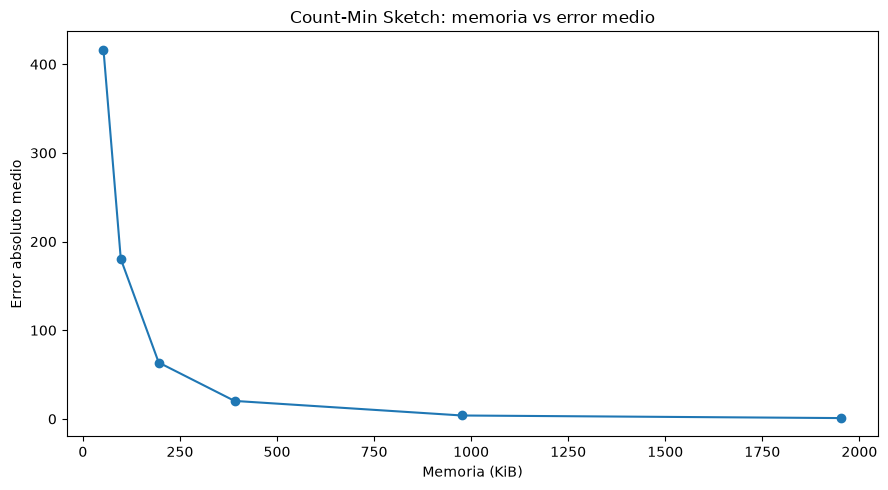

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    resultados_width_pd["memoria_kib"],
    resultados_width_pd["mae"],
    marker="o"
)

ax.set_title("Count-Min Sketch: memoria vs error medio")
ax.set_xlabel("Memoria (KiB)")
ax.set_ylabel("Error absoluto medio")

plt.tight_layout()
plt.show()

### Conclusión

El Count-Min Sketch mostró una reducción clara del error al aumentar el ancho de la estructura.

Con `width=2719` y `depth=5`, el MAE fue 416.38 usando aproximadamente 53 KiB. Al aumentar el ancho a 50,000, el MAE se redujo a 3.87 con un consumo cercano a 977 KiB.

El incremento de `depth` también reduce el error, aunque con rendimientos decrecientes y mayor consumo de memoria. Con `width=20000`, pasar de `depth=1` a `depth=5` redujo el MAE de 125.51 a 20.31, mientras que aumentarlo hasta 9 solo lo redujo adicionalmente a 13.92.

Como configuración de referencia se adopta `width=50000` y `depth=5`, que ofrece un buen compromiso entre precisión y memoria.

In [19]:
top10.to_csv(
    ARTIFACTS_DIR / "cms_top10.csv",
    index=False
)